# 🏦 Loan Approval & Credit Risk Analysis: End-to-End ML Training Pipeline

This notebook implements the complete machine learning workflow for predicting loan approval and credit risk:
1. **Data Ingestion**: Load dataset from `data/loan_data.csv`
2. **Preprocessing**: Encode target (`Loan_Status`), impute missing values (median for numerics, mode for categoricals)
3. **Feature Engineering**: Compute `TotalIncome`, `Debt_to_Income` ratio, and `Loan_to_Income` ratio
4. **Encoding**: One-hot encode categorical features
5. **Stratified Split**: 80/20 train/test split stratified on target
6. **Class Balancing**: Apply **SMOTE** on the training set only
7. **Model Benchmarking**: Train and compare **Logistic Regression**, **Decision Tree**, **Random Forest**, and **XGBoost**
8. **Model Comparison Table**: Compare all 4 models across Accuracy, Precision, Recall, F1, and ROC-AUC
9. **XGBoost Fine-Tuning**: Optimize the champion XGBoost classifier with **GridSearchCV**
10. **Test Set Evaluation**: Confusion Matrix heatmap, ROC Curve, and classification report
11. **Artifacts Export**: Save trained model to `backend/models/model.pkl` and 100-row pre-SMOTE background sample to `backend/models/background_data.csv`
12. **SHAP Explainability**: SHAP TreeExplainer feature importance and local waterfall analysis


In [1]:
# ── Environment & Library Imports ──────────────────────────────────────────
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import shap

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 10

print("All required packages successfully imported.")


All required packages successfully imported.


C:\Users\Me\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data Ingestion & Initial Inspection

We load the loan dataset from `data/loan_data.csv` and inspect its shape, columns, and initial null values.


In [2]:
data_path = os.path.join("..", "data", "loan_data.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "loan_data.csv")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")

# Drop Loan_ID identifier as it carries no predictive value
if "Loan_ID" in df.columns:
    df = df.drop(columns=["Loan_ID"])

df.head()


Dataset Shape: 614 rows × 13 columns


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2. Target Encoding & Missing Value Imputation

- **Target Encoding**: `Loan_Status` (`Y` → `1`, `N` → `0`)
- **Numeric Imputation (Median)**: `LoanAmount`, `Credit_History`
- **Categorical Imputation (Mode)**: `Gender`, `Married`, `Self_Employed`, `Dependents`, `Loan_Amount_Term`, `Property_Area`


In [3]:
# 1. Target Encoding
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

print("Target Class Distribution:")
print(df["Loan_Status"].value_counts(normalize=True).rename({1: "Approved (Y)", 0: "Rejected (N)"}))

# 2. Impute Numeric columns with Median
numeric_cols = ["LoanAmount", "Credit_History"]
for col in numeric_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f"Imputed numeric {col} with median: {median_val}")

# 3. Impute Categorical columns with Mode
categorical_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Loan_Amount_Term", "Property_Area"]
for col in categorical_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f"Imputed categorical {col} with mode: {mode_val}")

# Verify no missing values remain
print(f"\nRemaining null values across dataset: {df.isnull().sum().sum()}")


Target Class Distribution:
Loan_Status
Approved (Y)    0.687296
Rejected (N)    0.312704
Name: proportion, dtype: float64
Imputed numeric LoanAmount with median: 128.0
Imputed numeric Credit_History with median: 1.0
Imputed categorical Gender with mode: Male
Imputed categorical Married with mode: Yes
Imputed categorical Dependents with mode: 0
Imputed categorical Education with mode: Graduate
Imputed categorical Self_Employed with mode: No
Imputed categorical Loan_Amount_Term with mode: 360.0
Imputed categorical Property_Area with mode: Semiurban

Remaining null values across dataset: 0


## 3. Feature Engineering

We engineer three key financial domain features:
1. **TotalIncome**: Combined applicant and co-applicant monthly earnings.
   $$\text{TotalIncome} = \text{ApplicantIncome} + \text{CoapplicantIncome}$$
2. **Debt_to_Income**: Estimated monthly debt service (EMI) divided by total income.
   $$\text{Debt\_to\_Income} = \frac{\text{LoanAmount} \times 1000 / \text{Loan\_Amount\_Term}}{\text{TotalIncome} + \epsilon}$$
3. **Loan_to_Income**: Total loan requested relative to monthly total income.
   $$\text{Loan\_to\_Income} = \frac{\text{LoanAmount} \times 1000}{\text{TotalIncome} + \epsilon}$$


In [4]:
# Calculate engineered features
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

# Debt to income: (LoanAmount in thousands * 1000 / term in months) / TotalIncome
df["Debt_to_Income"] = (df["LoanAmount"] * 1000.0 / df["Loan_Amount_Term"]) / (df["TotalIncome"] + 1e-5)

# Loan to income: (LoanAmount in thousands * 1000) / TotalIncome
df["Loan_to_Income"] = (df["LoanAmount"] * 1000.0) / (df["TotalIncome"] + 1e-5)

print("Engineered Features Summary:")
display(df[["ApplicantIncome", "CoapplicantIncome", "TotalIncome", "LoanAmount", "Loan_Amount_Term", "Debt_to_Income", "Loan_to_Income"]].describe())


Engineered Features Summary:


,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,Loan_Amount_Term,Debt_to_Income,Loan_to_Income
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,7024.705081,145.752443,342.410423,0.077391,23.876787
std,6109.041673,2926.248369,6458.663872,84.107233,64.428629,0.079017,8.707161
min,150.000000,0.000000,1442.000000,9.000000,12.000000,0.007008,2.522916
25%,2877.500000,0.000000,4166.000000,100.250000,360.000000,0.055302,19.220552
50%,3812.500000,1188.500000,5416.500000,128.000000,360.000000,0.068970,24.129209
75%,5795.000000,2297.250000,7521.750000,164.750000,360.000000,0.081695,28.158020
max,81000.000000,41667.000000,81000.000000,700.000000,480.000000,1.236873,82.711644


## 4. One-Hot Encoding Categorical Variables

We one-hot encode all categorical variables (`Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`, `Property_Area`) with `drop_first=True` to prevent multicollinearity.


In [5]:
ohe_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]
df_encoded = pd.get_dummies(df, columns=ohe_cols, drop_first=True, dtype=int)

X = df_encoded.drop(columns=["Loan_Status"])
y = df_encoded["Loan_Status"]

feature_columns = list(X.columns)
print(f"Final Feature Matrix: {X.shape[0]} rows × {X.shape[1]} features")
print(f"\nFeature list ({len(feature_columns)}):\n{feature_columns}")


Final Feature Matrix: 614 rows × 17 features

Feature list (17):
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'Debt_to_Income', 'Loan_to_Income', 'Gender_Male', 'Married_Yes', 'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Education_Not Graduate', 'Self_Employed_Yes', 'Property_Area_Semiurban', 'Property_Area_Urban']


## 5. Stratified 80/20 Train / Test Split

We split into 80% training and 20% testing data, stratifying on `y` (`Loan_Status`) to preserve the target class ratio in both splits.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set : {X_test.shape[0]} samples")
print(f"Train Approval Rate: {y_train.mean():.2%}")
print(f"Test Approval Rate : {y_test.mean():.2%}")


Training set: 491 samples
Testing set : 123 samples
Train Approval Rate: 68.64%
Test Approval Rate : 69.11%


## 6. Class Imbalance Handling via SMOTE (Training Set Only)

To prevent data leakage, **SMOTE** (Synthetic Minority Over-sampling Technique) is applied **strictly to the training set**. The test set remains untouched to accurately reflect real-world distributions.


In [7]:
print(f"Before SMOTE - Training Class Counts:\n{y_train.value_counts().to_dict()}")

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE  - Balanced Training Class Counts:\n{pd.Series(y_train_res).value_counts().to_dict()}")
print(f"Balanced Training Matrix Shape: {X_train_res.shape}")


Before SMOTE - Training Class Counts:
{1: 337, 0: 154}



After SMOTE  - Balanced Training Class Counts:
{1: 337, 0: 337}
Balanced Training Matrix Shape: (674, 17)


## 7. Multi-Model Benchmark: Logistic Regression, Decision Tree, Random Forest & XGBoost

We train four distinct model families on the exact same SMOTE-balanced training set and evaluate them on the identical unseen test set:
1. **Logistic Regression**: Linear baseline with `StandardScaler` feature normalization.
2. **Decision Tree**: Non-linear, interpretable single-tree classifier (`max_depth=4`).
3. **Random Forest**: Bagging ensemble of 100 de-correlated decision trees.
4. **XGBoost**: Gradient boosting decision trees combining weak learners iteratively.


In [8]:
# Define all 4 candidate models
candidate_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),
    "XGBoost (Default)": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    )
}

# Train and evaluate all 4 models
benchmark_results = []
trained_candidates = {}

for name, model in candidate_models.items():
    model.fit(X_train_res, y_train_res)
    trained_candidates[name] = model
    
    y_pred_m = model.predict(X_test)
    y_prob_m = model.predict_proba(X_test)[:, 1]
    
    benchmark_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_m),
        "Precision": precision_score(y_test, y_pred_m),
        "Recall": recall_score(y_test, y_pred_m),
        "F1-Score": f1_score(y_test, y_pred_m),
        "ROC-AUC": roc_auc_score(y_test, y_prob_m)
    })

comparison_df = pd.DataFrame(benchmark_results)


## 8. Model Performance Comparison Table

Here is the comparative performance across all four models on the unseen holdout test set:


          MODEL PERFORMANCE COMPARISON (TEST SET)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,81.30%,89.74%,82.35%,85.89%,0.8839
1,Decision Tree,79.67%,84.09%,87.06%,85.55%,0.8433
2,Random Forest,86.99%,88.76%,92.94%,90.80%,0.8842
3,XGBoost (Default),82.11%,86.21%,88.24%,87.21%,0.8492


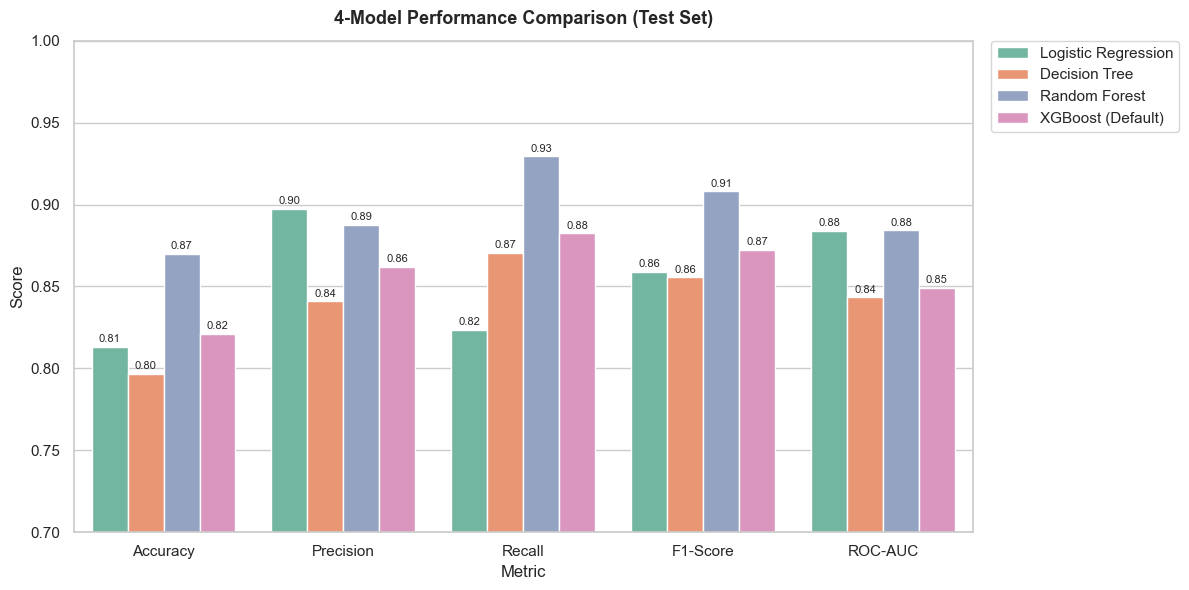

In [9]:
# Format and display the comparison table
display_table = comparison_df.copy()
for metric in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]:
    display_table[metric] = display_table[metric].apply(lambda x: f"{x * 100:.2f}%" if metric != "ROC-AUC" else f"{x:.4f}")

print("=====================================================================")
print("          MODEL PERFORMANCE COMPARISON (TEST SET)")
print("=====================================================================")
display(display_table)

# Visual comparison bar chart
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_df = comparison_df.melt(id_vars="Model", value_vars=metrics_to_plot, var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
chart = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2")
plt.title("4-Model Performance Comparison (Test Set)", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Score")
plt.ylim(0.70, 1.0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)

for p in chart.patches:
    h = p.get_height()
    if h > 0:
        chart.annotate(f"{h:.2f}",
                       (p.get_x() + p.get_width() / 2., h),
                       ha='center', va='bottom', fontsize=8, rotation=0, xytext=(0, 2),
                       textcoords='offset points')

plt.tight_layout()
plt.show()


## 9. Final XGBoost Classifier Hyperparameter Grid Search

XGBoost is selected for production deployment because of its exceptional handling of tabular feature interactions, gradient boosting efficiency, and direct integration with **TreeSHAP** for local/global explainability.

We perform 5-fold cross-validation over:
- `n_estimators`: `[50, 100, 150]`
- `max_depth`: `[3, 4, 5]`
- `learning_rate`: `[0.01, 0.05, 0.1]`


In [10]:
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
}

xgb_base = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train_res, y_train_res)

best_model = grid_search.best_estimator_
print(f"\nBest Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold Cross-Validated ROC-AUC: {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 27 candidates, totalling 135 fits



Best Hyperparameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
Best 5-Fold Cross-Validated ROC-AUC: 0.8836


## 10. Final XGBoost Test Set Evaluation & Diagnostics

Detailed evaluation of the tuned champion model on the unseen test set:
- **Confusion Matrix**
- **ROC-AUC Curve**
- **Full Classification Report**


FINAL XGBOOST TEST SET METRICS
  Accuracy : 82.93%
  Precision: 87.21%
  Recall   : 88.24%
  F1-Score : 87.72%
  ROC-AUC  : 0.8418

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.73      0.71      0.72        38
Approved (1)       0.87      0.88      0.88        85

    accuracy                           0.83       123
   macro avg       0.80      0.80      0.80       123
weighted avg       0.83      0.83      0.83       123



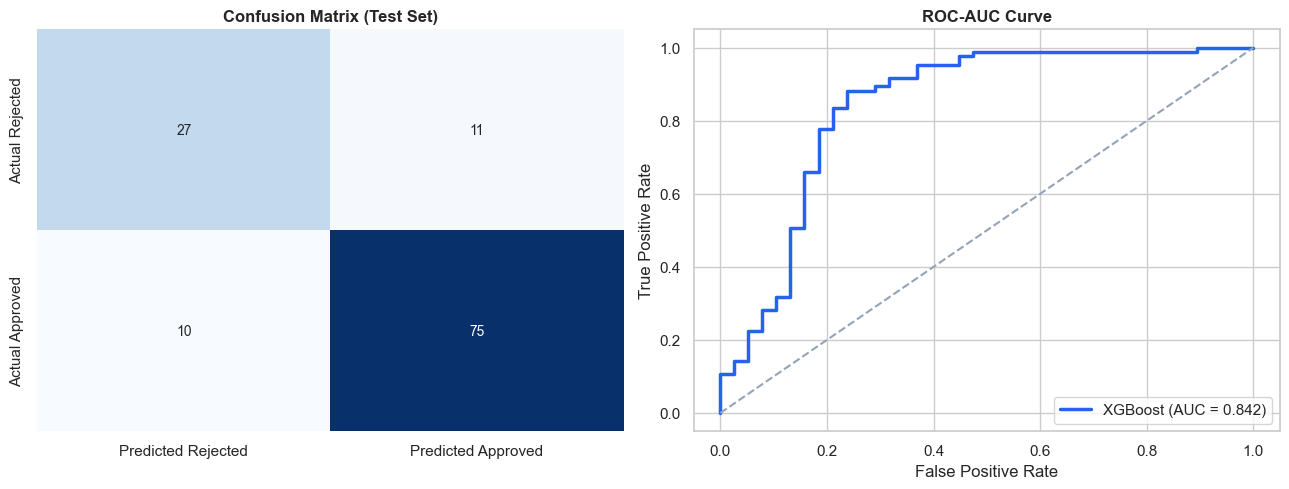

In [11]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print("=" * 45)
print("FINAL XGBOOST TEST SET METRICS")
print("=" * 45)
print(f"  Accuracy : {acc * 100:.2f}%")
print(f"  Precision: {prec * 100:.2f}%")
print(f"  Recall   : {rec * 100:.2f}%")
print(f"  F1-Score : {f1 * 100:.2f}%")
print(f"  ROC-AUC  : {roc:.4f}")
print("=" * 45)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Rejected (0)", "Approved (1)"]))

# Plot Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Predicted Rejected", "Predicted Approved"],
    yticklabels=["Actual Rejected", "Actual Approved"]
)
axes[0].set_title("Confusion Matrix (Test Set)", fontsize=12, fontweight="bold")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="#2563eb", lw=2.5, label=f"XGBoost (AUC = {roc:.3f})")
axes[1].plot([0, 1], [0, 1], color="#94a3b8", linestyle="--")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC-AUC Curve", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 11. Save Model & Pre-SMOTE Background Sample

We persist the trained model and feature metadata:
1. `backend/models/model.pkl`: Best trained XGBoost model using `joblib`.
2. `backend/models/background_data.csv`: 100-row random sample of **real, pre-SMOTE** training features for SHAP background reference.
3. `backend/models/feature_columns.json`: The exact feature column order required by the inference API.


In [12]:
backend_models_dir = os.path.join("..", "backend", "models")
if not os.path.exists(backend_models_dir):
    backend_models_dir = os.path.join("backend", "models")
os.makedirs(backend_models_dir, exist_ok=True)

# 1. Save Trained Model
model_save_path = os.path.join(backend_models_dir, "model.pkl")
joblib.dump(best_model, model_save_path)
print(f"Trained model saved to: {model_save_path}")

# Also copy to root models/
root_models_dir = os.path.join("..", "models") if os.path.exists(os.path.join("..", "models")) else "models"
if os.path.exists(root_models_dir):
    joblib.dump(best_model, os.path.join(root_models_dir, "model.pkl"))

# 2. Save 100-row pre-SMOTE background sample for SHAP
sample_size = min(100, len(X_train))
background_sample = X_train.sample(n=sample_size, random_state=42)
bg_save_path = os.path.join(backend_models_dir, "background_data.csv")
background_sample.to_csv(bg_save_path, index=False)
print(f"SHAP background data ({sample_size} rows) saved to: {bg_save_path}")

# 3. Save feature column order
feature_cols_path = os.path.join(backend_models_dir, "feature_columns.json")
with open(feature_cols_path, "w") as f:
    json.dump(feature_columns, f, indent=2)
print(f"Feature columns ({len(feature_columns)}) saved to: {feature_cols_path}")


Trained model saved to: ..\backend\models\model.pkl
SHAP background data (100 rows) saved to: ..\backend\models\background_data.csv
Feature columns (17) saved to: ..\backend\models\feature_columns.json


## 12. SHAP Explainability Verification

Using `shap.TreeExplainer` on the trained XGBoost model and the 100-row background dataset:
- We compute SHAP values for the test set.
- We plot global feature importance (SHAP Summary Beeswarm Plot).
- We inspect a single prediction's waterfall plot to demonstrate how feature contributions drive decisions.


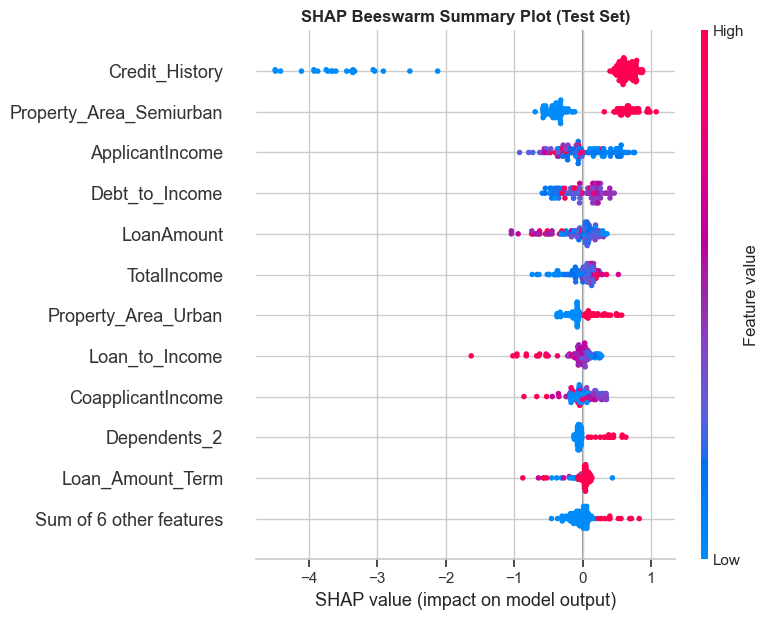

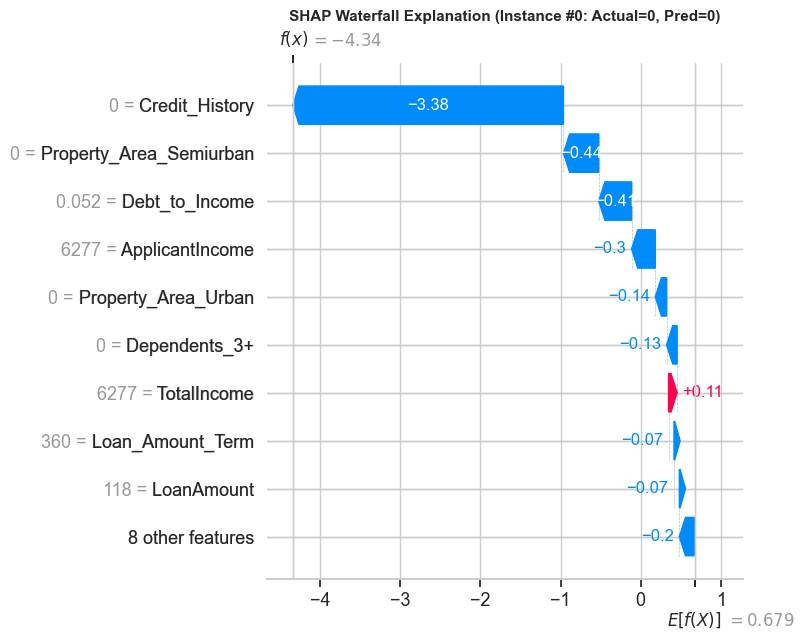

Complete pipeline executed successfully!


In [13]:
explainer = shap.TreeExplainer(best_model, data=background_sample)
shap_values = explainer(X_test)

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP Beeswarm Summary Plot (Test Set)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Local Waterfall Plot for the first test instance
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values[0], show=False)
plt.title(f"SHAP Waterfall Explanation (Instance #0: Actual={y_test.iloc[0]}, Pred={y_pred[0]})", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

print("Complete pipeline executed successfully!")
